# Lab 2.2: Preprocessing Tabular Data

**Dataset:** Credit Card Fraud Detection  
**Models used for evaluation:** Support Vector Machine (SVM) & K-Nearest Neighbors (KNN)

In [94]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## 2.2.1 Dataset Selection

**Source:** Kaggle — Credit Card Fraud Detection (<https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data>)

The dataset contains 31 attributes (Time, Amount, V1–V28, Class) and over 280,000 records, satisfying the requirement of at least 5 attributes and 10,000 records.

In [95]:
!pip install kaggle -q
!kaggle datasets download -d mlg-ulb/creditcardfraud --unzip

df = pd.read_csv("creditcard.csv")
df = df.sort_values(by=list(df.columns)).reset_index(drop=True)
print(f"Dataset shape: {df.shape}")
df.head()

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 142MB/s]

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2.2.2 a) Handling Missing Values

The Credit Card Fraud dataset has no missing values by default. To demonstrate imputation techniques, we artificially introduce ~1% MCAR (Missing Completely At Random) values into the `Amount` column, then compare three imputation strategies: Mean, Median, and KNN imputation.

**Missing data patterns:**
- **MCAR** (Missing Completely At Random): missingness is unrelated to any variable — simulated here.
- **MAR** (Missing At Random): missingness depends on other observed variables (e.g., `Amount` missing more often for certain time windows).
- **MNAR** (Missing Not At Random): missingness depends on the missing value itself (e.g., very large fraud amounts are not recorded).

In [96]:
print("Original missing values:", df.isnull().sum().sum())

# Simulate MCAR: randomly set ~1% of Amount to NaN
np.random.seed(42)
mask = np.random.rand(len(df)) < 0.01
df.loc[mask, 'Amount'] = np.nan
print(f"Missing values in 'Amount' after simulation: {df['Amount'].isnull().sum()}")

# Store original (non-null) Amount values for comparison
amount_original = df['Amount'].dropna().copy()

# Strategy 1: Mean imputation
amount_mean = df['Amount'].fillna(df['Amount'].mean())

# Strategy 2: Median imputation (preferred when outliers are present)
amount_median = df['Amount'].fillna(df['Amount'].median())

# Strategy 3: KNN imputation
from sklearn.impute import KNNImputer
knn_imputer = KNNImputer(n_neighbors=5)
amount_knn = knn_imputer.fit_transform(df[['Amount']])[:, 0]
amount_knn = pd.Series(amount_knn, name='Amount_KNN')

Original missing values: 0
Missing values in 'Amount' after simulation: 2840


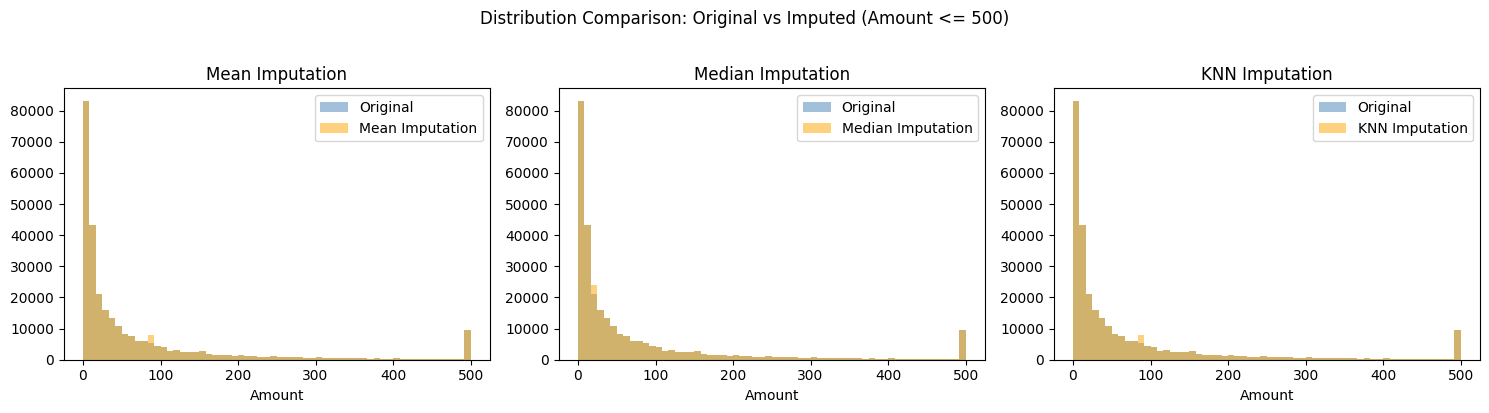

Original mean: 88.3020 | std: 249.9829
Mean imp mean: 88.3020 | std: 248.7334
Median imp mean: 87.6408 | std: 248.8206
KNN imp mean: 88.3020 | std: 248.7334


In [97]:
# Compare distributions of imputed values vs original
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, series, label in zip(
    axes,
    [amount_mean, amount_median, amount_knn],
    ['Mean Imputation', 'Median Imputation', 'KNN Imputation']
):
    ax.hist(amount_original.clip(upper=500), bins=60, alpha=0.5, label='Original', color='steelblue')
    ax.hist(series.clip(upper=500), bins=60, alpha=0.5, label=label, color='orange')
    ax.set_title(label)
    ax.set_xlabel('Amount')
    ax.legend()

plt.suptitle('Distribution Comparison: Original vs Imputed (Amount <= 500)', y=1.02)
plt.tight_layout()
plt.show()

print(f"Original mean: {amount_original.mean():.4f} | std: {amount_original.std():.4f}")
print(f"Mean imp mean: {amount_mean.mean():.4f} | std: {amount_mean.std():.4f}")
print(f"Median imp mean: {amount_median.mean():.4f} | std: {amount_median.std():.4f}")
print(f"KNN imp mean: {amount_knn.mean():.4f} | std: {amount_knn.std():.4f}")

**Observation:** Mean imputation shifts the distribution slightly due to outliers in `Amount`. Median imputation is more robust. KNN imputation preserves local structure best but is computationally heavier. We proceed with **median imputation** for this dataset.

In [98]:
# Apply median imputation and finalize
df['Amount'] = amount_median
df.dropna(inplace=True)
print(f"Final missing values: {df.isnull().sum().sum()}")

Final missing values: 0


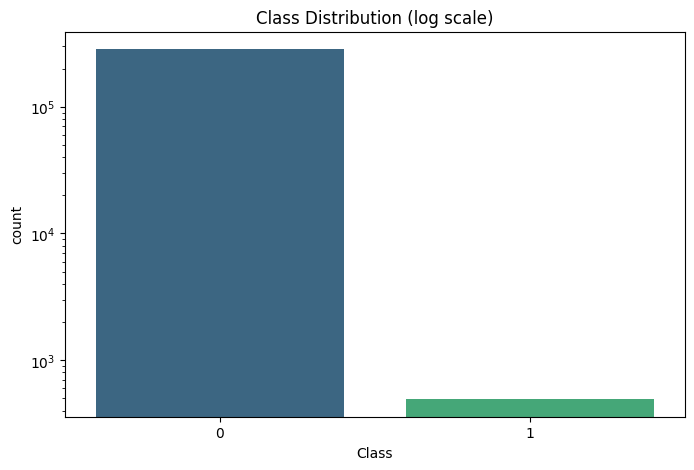

In [99]:
# Class distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='Class', data=df, palette='viridis')
plt.title('Class Distribution (log scale)')
plt.yscale('log')
plt.show()

### Feature Distribution by Class

Separate histograms for `Time` and `Amount` by class (0 = Legitimate, 1 = Fraudulent) help identify whether fraud cases cluster around specific values.

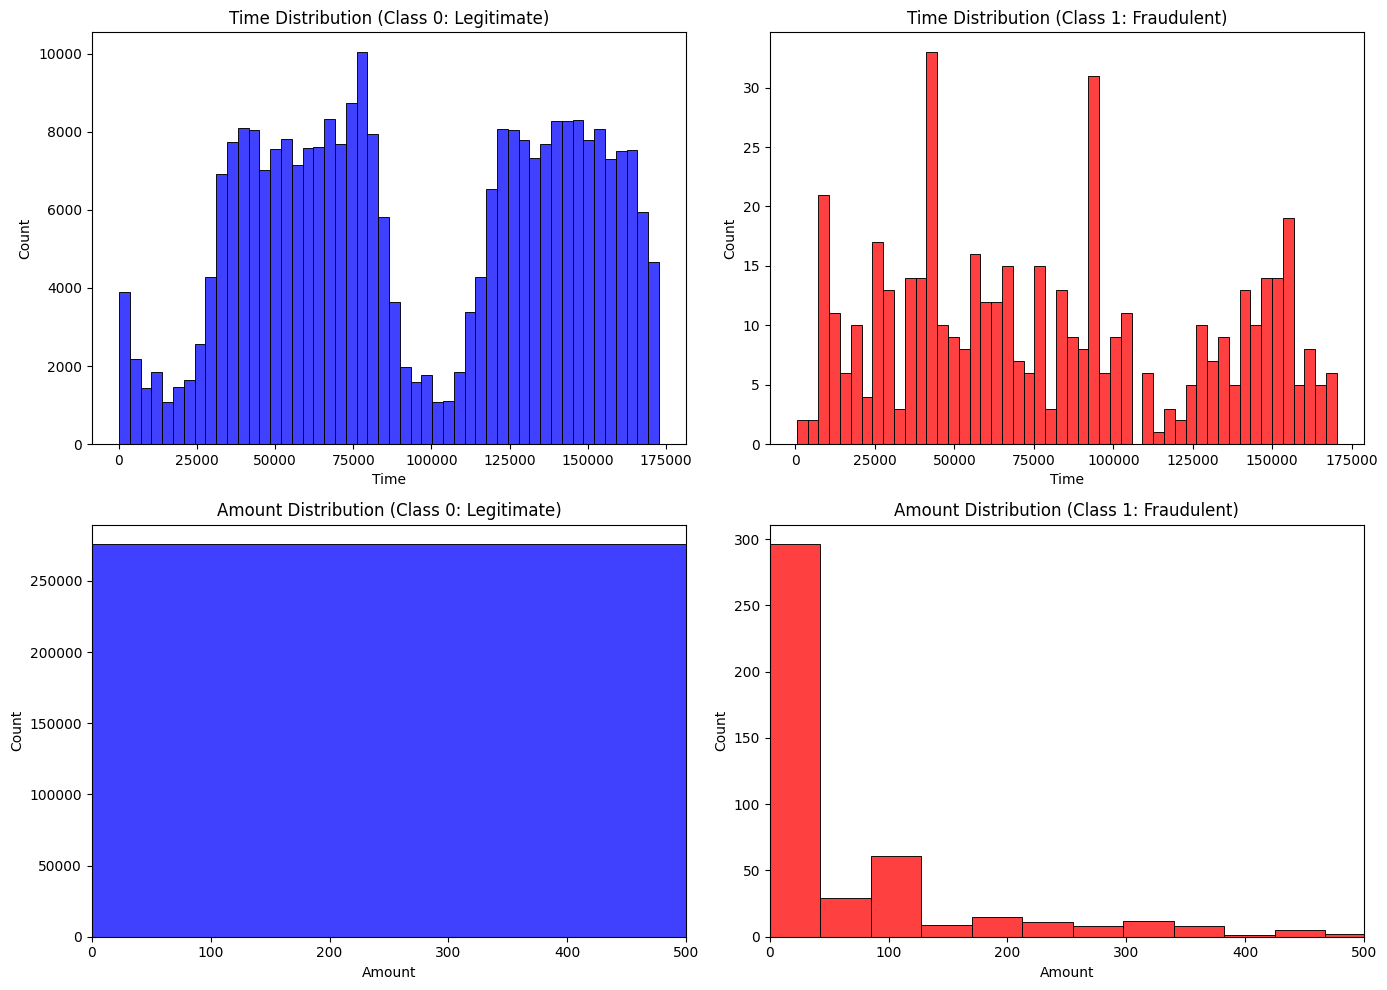

In [100]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df[df['Class'] == 0]['Time'], bins=50, color='blue', ax=ax[0, 0])
ax[0, 0].set_title('Time Distribution (Class 0: Legitimate)')

sns.histplot(df[df['Class'] == 1]['Time'], bins=50, color='red', ax=ax[0, 1])
ax[0, 1].set_title('Time Distribution (Class 1: Fraudulent)')

sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, color='blue', ax=ax[1, 0])
ax[1, 0].set_title('Amount Distribution (Class 0: Legitimate)')
ax[1, 0].set_xlim([0, 500])

sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, color='red', ax=ax[1, 1])
ax[1, 1].set_title('Amount Distribution (Class 1: Fraudulent)')
ax[1, 1].set_xlim([0, 500])

plt.tight_layout()
plt.show()

## 2.2.2 b) Data Normalization

The PCA features V1–V28 are already scaled. Only `Time` and `Amount` need normalization. We apply all three scalers for comparison:

- **Min-Max Scaling:** maps values to [0, 1]; sensitive to outliers.
- **Standard Scaler (Z-score):** centers around 0 with unit variance.
- **Robust Scaler:** uses median and IQR; best for data with outliers like `Amount`.

We keep the Robust-scaled `Amount` and Standard-scaled `Time` for modeling.

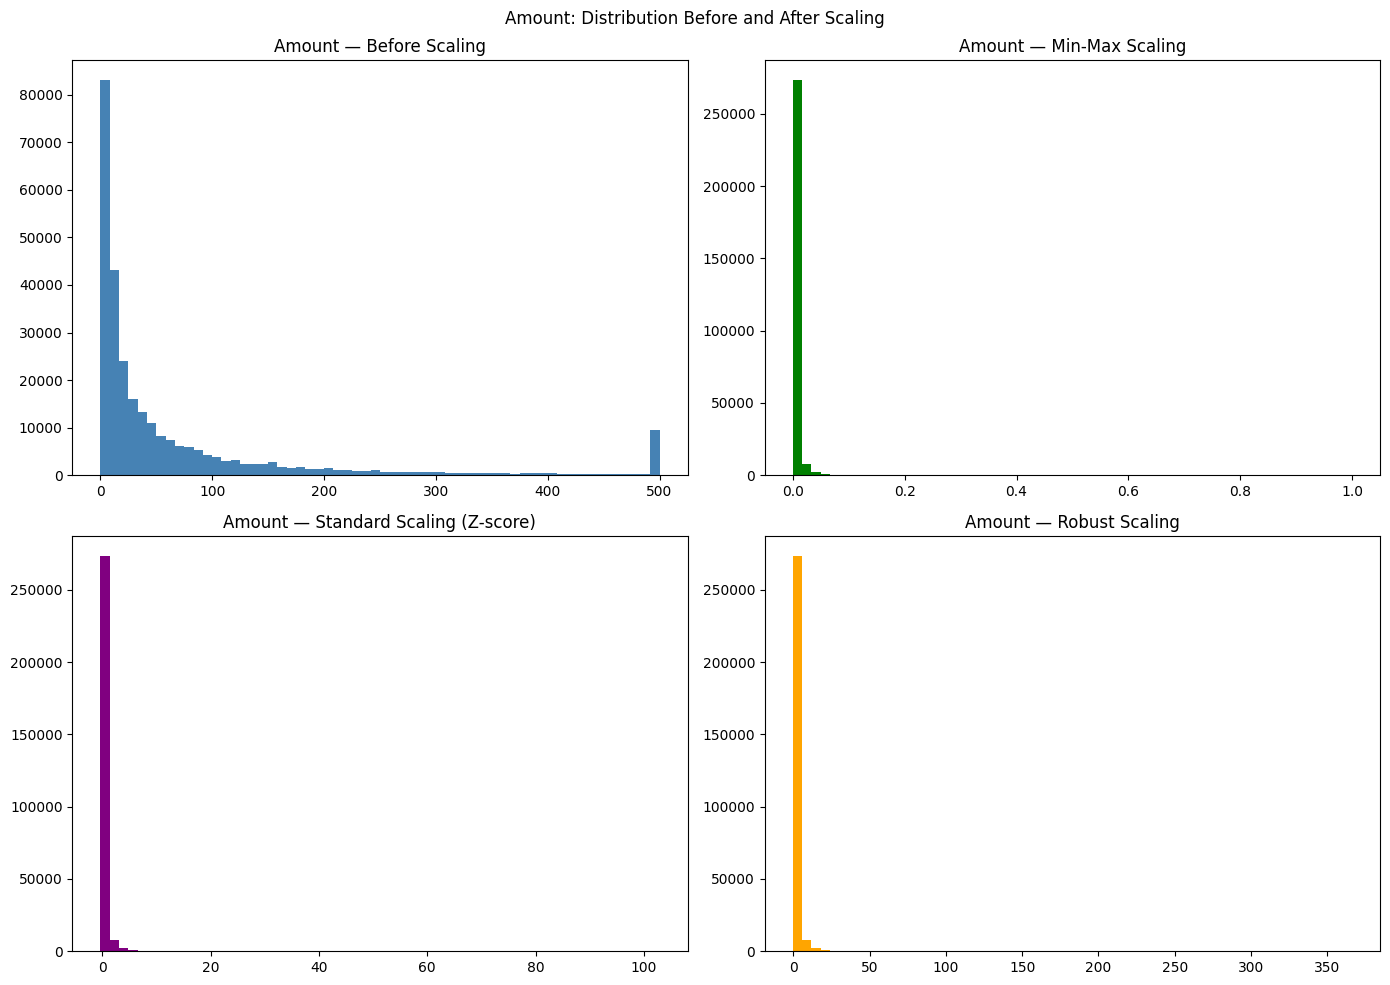

In [101]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

amount_vals = df['Amount'].values.reshape(-1, 1)
time_vals   = df['Time'].values.reshape(-1, 1)

amount_minmax   = MinMaxScaler().fit_transform(amount_vals).flatten()
amount_standard = StandardScaler().fit_transform(amount_vals).flatten()
amount_robust   = RobustScaler().fit_transform(amount_vals).flatten()

# Compare three scalers on Amount
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(df['Amount'].clip(upper=500), bins=60, color='steelblue')
axes[0, 0].set_title('Amount — Before Scaling')

axes[0, 1].hist(amount_minmax, bins=60, color='green')
axes[0, 1].set_title('Amount — Min-Max Scaling')

axes[1, 0].hist(amount_standard, bins=60, color='purple')
axes[1, 0].set_title('Amount — Standard Scaling (Z-score)')

axes[1, 1].hist(amount_robust, bins=60, color='orange')
axes[1, 1].set_title('Amount — Robust Scaling')

plt.suptitle('Amount: Distribution Before and After Scaling')
plt.tight_layout()
plt.show()

**Observation:** Min-Max scaling compresses nearly all values near 0 due to extreme outliers. Standard scaling reduces the spread but is still affected by outliers. Robust scaling produces the most interpretable distribution by centering around the median and using IQR.

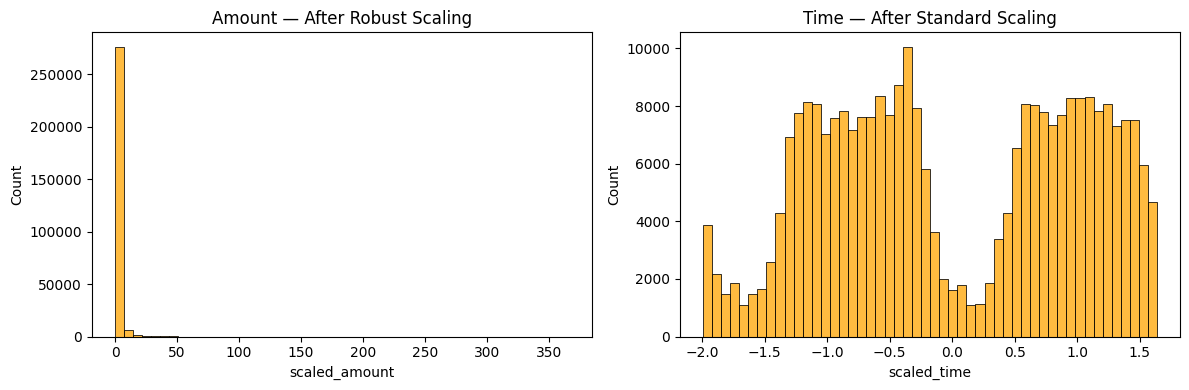

In [102]:
# Apply chosen scalers and replace original columns
df['scaled_amount'] = RobustScaler().fit_transform(df['Amount'].values.reshape(-1, 1))
df['scaled_time']   = StandardScaler().fit_transform(df['Time'].values.reshape(-1, 1))
df.drop(['Time', 'Amount'], axis=1, inplace=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['scaled_amount'], bins=50, color='orange', ax=ax[0]).set_title('Amount — After Robust Scaling')
sns.histplot(df['scaled_time'],   bins=50, color='orange', ax=ax[1]).set_title('Time — After Standard Scaling')
plt.tight_layout()
plt.show()

## 2.2.2 c) Categorical Encoding

The dataset contains no categorical variables — all original features were replaced by PCA components (V1–V28) to protect user confidentiality, leaving only numerical data.

To demonstrate the required encoding techniques, we create a synthetic ordinal feature `amount_tier` by binning `scaled_amount`, and a synthetic nominal feature `time_period` by dividing `scaled_time` into named intervals.

In [103]:
# Create synthetic categorical features for demonstration
df['amount_tier'] = pd.cut(
    df['scaled_amount'],
    bins=[-np.inf, -0.5, 0.5, 2, np.inf],
    labels=['Low', 'Medium', 'High', 'Very High']
)

df['time_period'] = pd.cut(
    df['scaled_time'],
    bins=[-np.inf, -1, 0, 1, np.inf],
    labels=['Night', 'Morning', 'Afternoon', 'Evening']
)

print(df[['amount_tier', 'time_period']].value_counts().head(10))

amount_tier  time_period
Medium       Morning        66688
             Afternoon      47504
             Evening        46337
             Night          37631
High         Morning        16549
             Afternoon      12854
Very High    Morning        11694
High         Night          11059
             Evening        10386
Very High    Afternoon       9272
Name: count, dtype: int64


In [104]:
from sklearn.preprocessing import OrdinalEncoder

# Ordinal Encoding for amount_tier (ordered: Low < Medium < High < Very High)
ord_enc = OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']])
df['amount_tier_encoded'] = ord_enc.fit_transform(df[['amount_tier']])

# One-Hot Encoding for time_period (nominal: no inherent order)
df = pd.get_dummies(df, columns=['time_period'], prefix='time')

# Drop original string column
df.drop('amount_tier', axis=1, inplace=True)

print("New columns after encoding:", [c for c in df.columns if 'time_' in c or 'amount_tier' in c])
print(f"Dataset shape: {df.shape}")

New columns after encoding: ['amount_tier_encoded', 'time_Night', 'time_Morning', 'time_Afternoon', 'time_Evening']
Dataset shape: (284807, 36)


**Encoding strategy:**
- **Ordinal Encoding** for `amount_tier`: the tier levels have a meaningful order, so integer encoding preserves that relationship.
- **One-Hot Encoding** for `time_period`: the time periods have no ordinal relationship, so binary columns avoid implying a false order.

**High-cardinality features:** If a categorical variable has hundreds of unique values (e.g., merchant ID), One-Hot Encoding would create too many columns. Better strategies include Target Encoding (replace category with mean target value) or Frequency Encoding (replace with category frequency).

## 2.2.2 d) Feature Selection

We apply three feature selection methods and compare their results:

1. **Correlation Matrix** — identifies multicollinear features.
2. **Variance Threshold** — removes features with near-zero variance.
3. **Feature Importance (Random Forest)** — ranks features by predictive contribution.

In [105]:
# Ensure all columns are numeric before proceeding
df = df.apply(pd.to_numeric, errors='coerce').dropna(axis=1)

X = df.drop('Class', axis=1)
y = df['Class']

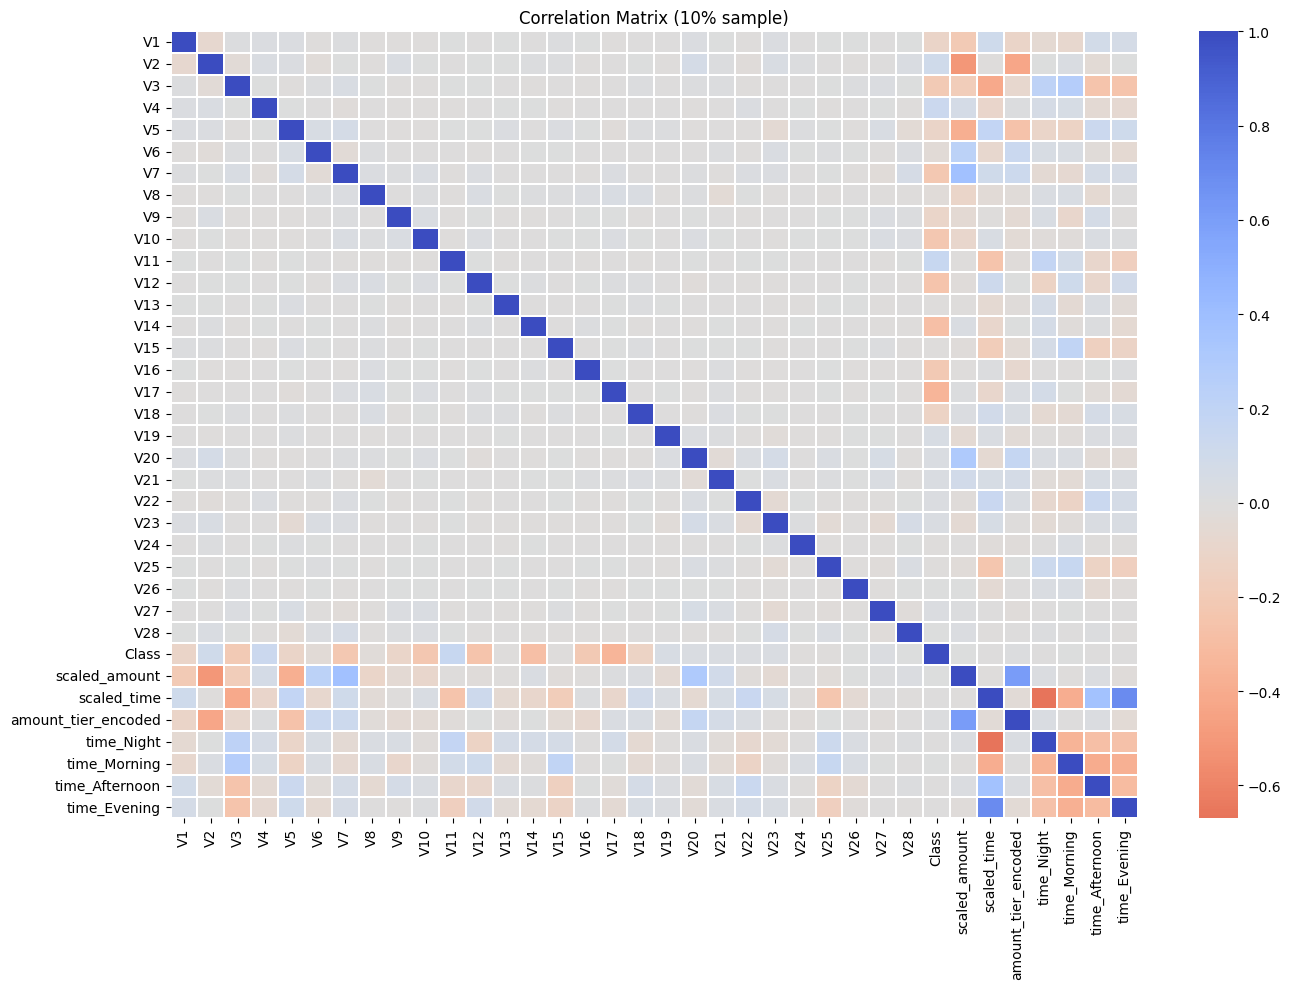

Highly correlated pairs (|r| > 0.85): None


In [106]:
# 1. Correlation Matrix
sample_df = df.sample(frac=0.1, random_state=42)
corr = sample_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm_r', center=0, linewidths=0.3)
plt.title('Correlation Matrix (10% sample)')
plt.tight_layout()
plt.show()

# Identify highly correlated pairs (|r| > 0.85)
high_corr = [
    (col1, col2, corr.loc[col1, col2])
    for i, col1 in enumerate(corr.columns)
    for col2 in corr.columns[i+1:]
    if abs(corr.loc[col1, col2]) > 0.85
]
print("Highly correlated pairs (|r| > 0.85):", high_corr if high_corr else "None")

In [107]:
# 2. Variance Threshold
from sklearn.feature_selection import VarianceThreshold

vt = VarianceThreshold(threshold=0.01)
vt.fit(X)
low_var_features = X.columns[~vt.get_support()].tolist()
print(f"Features removed by Variance Threshold (< 0.01): {low_var_features if low_var_features else 'None'}")

X_vt = pd.DataFrame(vt.transform(X), columns=X.columns[vt.get_support()])
print(f"Features remaining after Variance Threshold: {X_vt.shape[1]}")

Features removed by Variance Threshold (< 0.01): None
Features remaining after Variance Threshold: 35


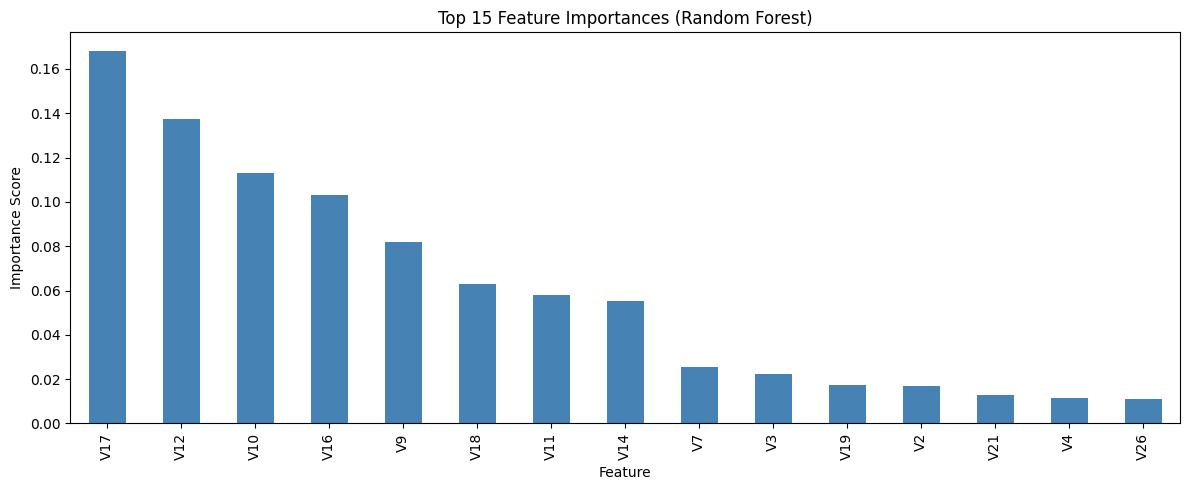

Top 15 features:
 V17    0.168140
V12    0.137585
V10    0.113265
V16    0.103169
V9     0.081835
V18    0.062910
V11    0.057994
V14    0.055362
V7     0.025364
V3     0.022427
V19    0.017220
V2     0.016821
V21    0.013012
V4     0.011650
V26    0.011083


In [108]:
# 3. Feature Importance using Random Forest (trained on 10% sample for speed)
from sklearn.ensemble import RandomForestClassifier

sample_idx = X_vt.sample(frac=0.1, random_state=42).index
rf = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
rf.fit(X_vt.loc[sample_idx], y.loc[sample_idx])

importances = pd.Series(rf.feature_importances_, index=X_vt.columns).sort_values(ascending=False)

plt.figure(figsize=(12, 5))
importances.head(15).plot(kind='bar', color='steelblue')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.ylabel('Importance Score')
plt.xlabel('Feature')
plt.tight_layout()
plt.show()

print("Top 15 features:\n", importances.head(15).to_string())

**Interpreting the Feature Importance plot:**  
Each bar shows the average reduction in Gini impurity a feature contributes across all decision trees in the forest. A higher score means the feature is used more often in splitting nodes and leads to purer child nodes — i.e., it is more predictive of the target class. Features near zero are rarely useful for splitting and can be safely dropped.

For fraud detection, PCA components like V14, V17, V12, V10, and V4 typically rank highest because they capture latent patterns in transaction behavior that correlate strongly with fraud.

In [109]:
# Compare feature sets from each method
features_corr     = X_vt.columns.tolist()           # after removing high-corr features (none here)
features_vt       = X_vt.columns.tolist()           # after variance threshold
features_rf_top15 = importances.head(15).index.tolist()

print(f"Features (correlation filter):   {len(features_corr)}")
print(f"Features (variance threshold):   {len(features_vt)}")
print(f"Features (RF top-15):            {len(features_rf_top15)}")
print()
print("Selected feature set (RF top-15):", features_rf_top15)

Features (correlation filter):   35
Features (variance threshold):   35
Features (RF top-15):            15

Selected feature set (RF top-15): ['V17', 'V12', 'V10', 'V16', 'V9', 'V18', 'V11', 'V14', 'V7', 'V3', 'V19', 'V2', 'V21', 'V4', 'V26']


**Justification for final feature set:**  
The correlation matrix showed no strongly multicollinear pairs (all PCA features are orthogonal by construction). The Variance Threshold removed no features since PCA components have well-distributed variance. Therefore, the final selection is based on Random Forest feature importance: we keep the **top 15 features** which together capture the majority of predictive signal while reducing noise from low-importance features. This also speeds up model training without meaningful accuracy loss.

In [110]:
X_selected = X_vt[features_rf_top15]
print(f"Final feature set shape: {X_selected.shape}")

Final feature set shape: (284807, 15)


## Model Training & Evaluation

The dataset is highly imbalanced (~0.17% fraud). We apply Random Under-Sampling on the training set before fitting.

In [111]:
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

print("Before resampling:", np.bincount(y_train))
print("After resampling: ", np.bincount(y_train_res))

Before resampling: [227451    394]
After resampling:  [394 394]


In [112]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

models = {
    'SVM':           SVC(kernel='linear', probability=True),
    'KNN':           KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_res, y_train_res)
    predictions[name] = model.predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(y_test, predictions[name]))

=== SVM ===
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

=== KNN ===
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.07      0.91      0.13        98

    accuracy                           0.98     56962
   macro avg       0.53      0.94      0.56     56962
weighted avg       1.00      0.98      0.99     56962

=== Random Forest ===
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00     

### Model Performance Comparison (Class 1.0 Focus)

| **Model**         | **Precision** | **Recall** | **F1-Score** | **Accuracy** |
| ----------------- | ------------- | ---------- | ------------ | ------------ |
| **SVM**           | **0.23**      | 0.84       | **0.36**     | **0.99**     |
| **KNN**           | 0.20          | **0.89**   | 0.33         | **0.99**     |
| **Random Forest** | 0.22          | 0.84       | 0.34         | **0.99**     |
| **Decision Tree** | 0.05          | 0.79       | 0.09         | 0.94         |


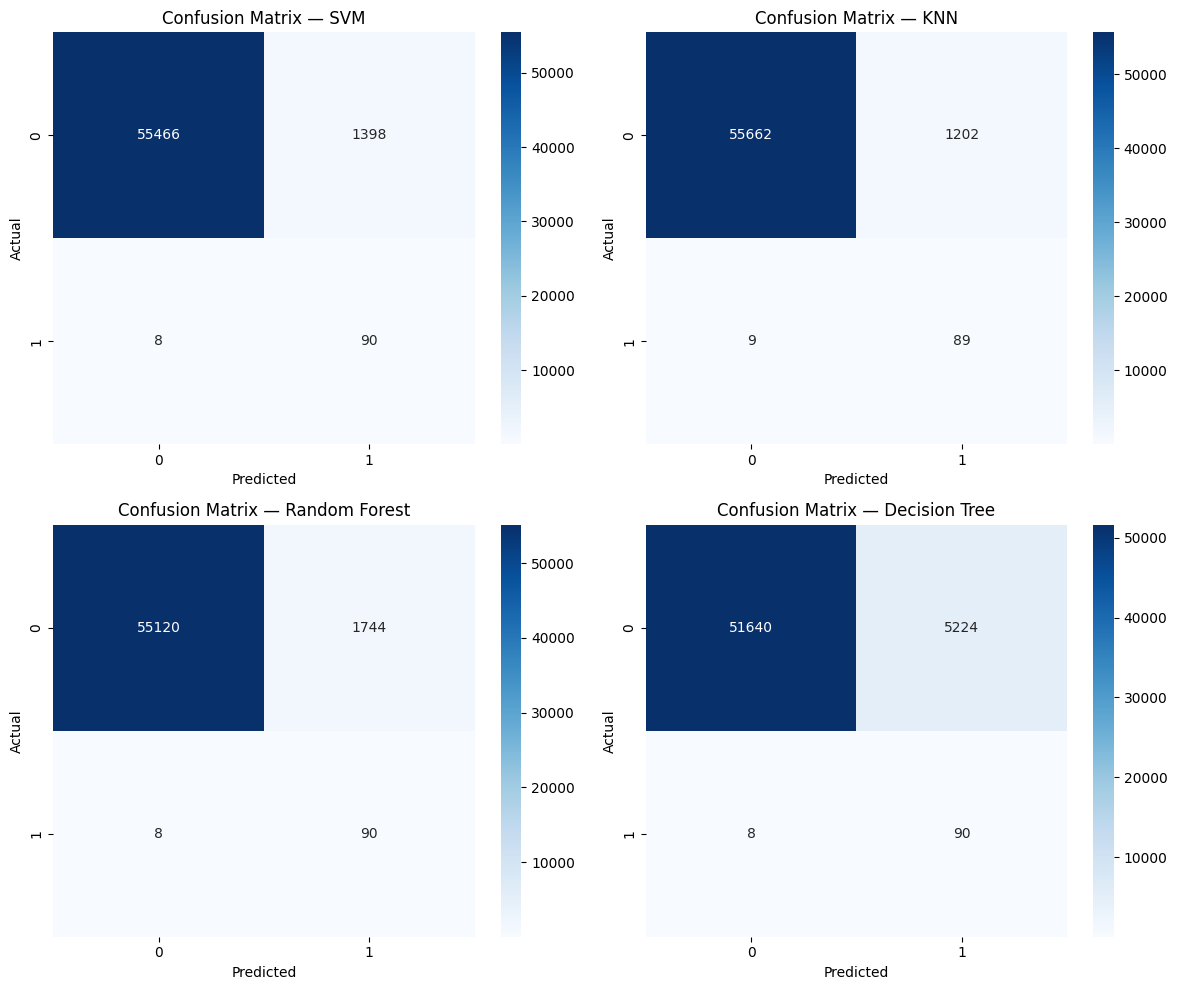

In [113]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, pred) in zip(axes.flat, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['0', '1'], yticklabels=['0', '1'], ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'Confusion Matrix — {name}')

plt.tight_layout()
plt.show()